In [23]:
import os
import json
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as T
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import cv2
import lpips
import numpy as np
import pandas as pd
from tqdm.notebook import tqdm
from skimage.metrics import structural_similarity as calculate_ssim
from scipy.spatial.distance import directed_hausdorff
from torchvision.utils import save_image
from flip_loss import LDRFLIPLoss

In [24]:
def prepareDevice():
    device = torch.device("cpu")

    if torch.cuda.is_available():
        device = torch.device("cuda")
        torch.cuda.manual_seed(42)
        torch.cuda.manual_seed_all(42)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        print("Using CUDA")
    else:
        print("Using CPU")

    return device

device = prepareDevice()

Using CUDA


In [25]:
class PhongDataset(Dataset):
    def __init__(self, root_dir, json_file, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        
        json_path = os.path.join(root_dir, json_file)
        with open(json_path, 'r', encoding='utf-8') as f:
            self.data = json.load(f)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        
        img_path = os.path.join(self.root_dir, item['image_name'])
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        obj_pos_raw = torch.tensor(item['model_translation'])
        light_pos_raw = torch.tensor(item['light_position'])
        diffuse = torch.tensor(item['material_diffuse'])
        shininess_raw = torch.tensor([item['material_shininess']])        
        rel_light_raw = torch.tensor(item['features_for_network']['relative_light_position']) 
        inv_dist = torch.tensor([item['features_for_network']['inverse_depth']])
        obj_pos = obj_pos_raw / 20.0
        light_pos = light_pos_raw / 20.0
        shininess = shininess_raw / 20.0
        rel_light = rel_light_raw / 40.0

        params = torch.cat([
            obj_pos,      
            diffuse,      
            shininess,    
            light_pos,    
            rel_light,    
            inv_dist 
        ], dim=0).float()

        return params, image

In [26]:
transforms = T.Compose([
    T.Resize((128, 128)),
    T.ToTensor(),
    T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

EXTRACT_PATH = '/output/'
dataset_path = 'output/'

dataset = PhongDataset(dataset_path, 'scene_parameters.json', transform=transforms)

train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
train_set, test_set = torch.utils.data.random_split(dataset, [train_size, test_size])

train_loader = DataLoader(train_set, batch_size=64, shuffle=True)
test_loader = DataLoader(test_set, batch_size=64, shuffle=False)

print(f"Train length: {len(train_set)}, Test length: {len(test_set)}")


Train length: 2400, Test length: 600


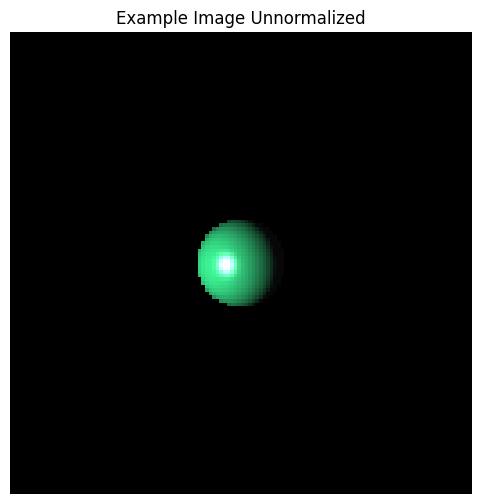

Vector of parameters (14 features) for this image:
tensor([ 0.5983,  0.6151,  0.3650,  0.2087,  0.9306,  0.5562,  0.6938, -0.7360,
        -0.1933,  0.4116, -0.6671, -0.4042,  0.0233,  0.0788])


In [27]:
def show_example(dataset):
    params, image_tensor = dataset[0]
    image_unnorm = (image_tensor * 0.5) + 0.5
    image_display = image_unnorm.permute(1, 2, 0).numpy()
    
    plt.figure(figsize=(6, 6))
    plt.imshow(image_display)
    plt.title("Example Image Unnormalized")
    plt.axis("off")
    plt.show()
    
    print("Vector of parameters (14 features) for this image:")
    print(params)

show_example(dataset)

# 1st Model version - Generator without noise input

In [28]:
import torch
import torch.nn as nn

class Generator(nn.Module):
    def __init__(self, condition_dim=14, base_features=512, out_channels=3, num_upsample_blocks=5, latent_size=4):
        super().__init__()
        self.latent_size = latent_size
        self.base_features = base_features
        
        self.cond_to_feature_map = nn.Sequential(
            nn.Linear(condition_dim, base_features * latent_size * latent_size),
            nn.ReLU(True)
        )
        
        layers = []
        in_features = base_features
        
        for _ in range(num_upsample_blocks - 1):
            out_features = in_features // 2
            layers.extend([
                nn.ConvTranspose2d(in_features, out_features, kernel_size=4, stride=2, padding=1, bias=False),
                nn.BatchNorm2d(out_features),
                nn.ReLU(True)
            ])
            in_features = out_features
            
        layers.extend([
            nn.ConvTranspose2d(in_features, out_channels, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()
        ])

        self.upsample = nn.Sequential(*layers)

    def forward(self, cond):
        x = self.cond_to_feature_map(cond)
        x = x.view(-1, self.base_features, self.latent_size, self.latent_size) 
        return self.upsample(x)

In [29]:
class Discriminator(nn.Module):
    def __init__(self, input_channels=3, condition_dim=14, base_features=64, num_downsample_blocks=5, final_spatial_size=4):
        super().__init__()
        
        total_input_channels = input_channels + condition_dim
        layers = []
        
        in_channels = total_input_channels
        out_channels = base_features
        
        for i in range(num_downsample_blocks):
            layers.append(
                nn.Conv2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=False if i != 0 else True)
            )
            
            if i != 0:
                layers.append(nn.BatchNorm2d(out_channels))
                
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            
            in_channels = out_channels
            out_channels *= 2
            
        layers.extend([
            nn.Flatten(),
            nn.Linear(in_channels * final_spatial_size * final_spatial_size, 1),
            nn.Sigmoid()
        ])
        
        self.model = nn.Sequential(*layers)

    def forward(self, image, cond):
        cond_expanded = cond.view(cond.size(0), cond.size(1), 1, 1)
        cond_expanded = cond_expanded.repeat(1, 1, image.size(2), image.size(3))
        x = torch.cat([image, cond_expanded], dim=1)
        return self.model(x)

In [30]:
def warmup_generator(generator, train_loader, criterion_l1, loss_fn_vgg, optimizer, device, epochs=5, lambda_l1=100.0, lambda_lpips=10.0):
    print("Warm up generator")
    generator.train()
    for epoch in range(epochs):
        epoch_loss = 0
        for cond, real_imgs in train_loader:
            cond, real_imgs = cond.to(device), real_imgs.to(device)
            
            optimizer.zero_grad()
            fake_imgs = generator(cond)
            
            loss_G_l1 = criterion_l1(fake_imgs, real_imgs) * lambda_l1
            loss_G_lpips = loss_fn_vgg(fake_imgs, real_imgs).mean() * lambda_lpips
            loss_G = loss_G_l1 + loss_G_lpips
            loss_G.backward()
            optimizer.step()
            
            epoch_loss += loss_G.item()
            
        print(f"Warm up Epoch [{epoch+1}/{epochs}] | Loss: {epoch_loss/len(train_loader):.4f}")
    return generator


def validate(generator, discriminator, test_loader, criterion_gan, criterion_l1, loss_fn_vgg, device, lambda_l1=100.0, lambda_lpips=10.0):
    generator.eval()
    discriminator.eval()
    val_d_loss = 0
    val_g_loss = 0
    
    with torch.no_grad():
        for cond, real_imgs in test_loader:
            cond, real_imgs = cond.to(device), real_imgs.to(device)
            batch_size = real_imgs.size(0)   
            fake_imgs = generator(cond)
            pred_real = discriminator(real_imgs, cond)
            loss_D_real = criterion_gan(pred_real, torch.ones((batch_size, 1), device=device))  
            pred_fake = discriminator(fake_imgs, cond)
            loss_D_fake = criterion_gan(pred_fake, torch.zeros((batch_size, 1), device=device))
            loss_D = (loss_D_real + loss_D_fake) * 0.5
            val_d_loss += loss_D.item()
            pred_fake_for_G = discriminator(fake_imgs, cond)
            loss_G_gan = criterion_gan(pred_fake_for_G, torch.ones((batch_size, 1), device=device))
            loss_G_l1 = criterion_l1(fake_imgs, real_imgs) * lambda_l1
            loss_G_lpips = loss_fn_vgg(fake_imgs, real_imgs).mean() * lambda_lpips
            loss_G = loss_G_gan + loss_G_l1 + loss_G_lpips
            val_g_loss += loss_G.item()

    avg_d_loss = val_d_loss / len(test_loader)
    avg_g_loss = val_g_loss / len(test_loader)
    
    return avg_d_loss, avg_g_loss

def train_gan(generator, discriminator, train_loader, device, epochs=50, lambda_l1=100.0):
    print("Training GAN")
    lambda_lpips = 10.0
    
    criterion_gan = nn.BCELoss()
    criterion_l1 = nn.L1Loss()
    
    loss_fn_vgg = lpips.LPIPS(net='alex').to(device)
    for param in loss_fn_vgg.parameters():
        param.requires_grad = False
    
    generator_optimizer = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
    discriminator_optimizer = optim.Adam(discriminator.parameters(), lr=0.0001, betas=(0.5, 0.999))
    
    generator = warmup_generator(generator, train_loader, criterion_l1, loss_fn_vgg, generator_optimizer, device, epochs=7, 
                                 lambda_l1=lambda_l1, lambda_lpips=lambda_lpips)
    best_val_g = float('inf')
    
    for epoch in range(epochs):
        generator.train()
        discriminator.train()
        
        running_d_loss = 0.0
        running_g_loss = 0.0
        
        for cond, real_imgs in train_loader:
            cond, real_imgs = cond.to(device), real_imgs.to(device)
            batch_size = real_imgs.size(0)
            
            real_labels = torch.full((batch_size, 1), 0.9, device=device)
            fake_labels = torch.zeros((batch_size, 1), device=device)
            
            discriminator_optimizer.zero_grad()
            
            fake_imgs = generator(cond)
            
            pred_real = discriminator(real_imgs, cond)
            loss_D_real = criterion_gan(pred_real, real_labels)
            
            pred_fake = discriminator(fake_imgs.detach(), cond)
            loss_D_fake = criterion_gan(pred_fake, fake_labels)
            
            loss_D = (loss_D_real + loss_D_fake) * 0.5
            loss_D.backward()
            discriminator_optimizer.step()
            
            generator_optimizer.zero_grad()
            
            pred_fake_for_G = discriminator(fake_imgs, cond)
            
            loss_G_gan = criterion_gan(pred_fake_for_G, torch.ones((batch_size, 1), device=device))
            loss_G_l1 = criterion_l1(fake_imgs, real_imgs) * lambda_l1
            loss_G_lpips = loss_fn_vgg(fake_imgs, real_imgs).mean() * lambda_lpips
            
            loss_G = loss_G_gan + loss_G_l1 + loss_G_lpips
            loss_G.backward()
            generator_optimizer.step()
            
            running_d_loss += loss_D.item()
            running_g_loss += loss_G.item()
            
        val_avg_d, val_avg_g = validate(generator, discriminator, test_loader, criterion_gan, criterion_l1, loss_fn_vgg, device, lambda_l1, lambda_lpips=lambda_lpips)
                 
        print(f"Epoch [{epoch+1}/{epochs}]")
        print(f"Train Loss Discriminator: {running_d_loss/len(train_loader):.4f} | Train Loss Generator: {running_g_loss/len(train_loader):.4f}")
        print(f"Validation Loss Discriminator: {val_avg_d:.4f} | Validation Loss Generator: {val_avg_g:.4f}")
        
        if val_avg_g < best_val_g:
            best_val_g = val_avg_g
            print(f"New Best Generator found. Saving...")
            torch.save(generator.state_dict(), 'best_generator.pth')
            torch.save(discriminator.state_dict(), 'best_discriminator.pth')

generator = Generator().to(device)
discriminator = Discriminator().to(device)

train_gan(generator, discriminator, train_loader, device, epochs=50, lambda_l1=100.0)

Training GAN
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


c:\Users\Nel\OneDrive\Pulpit\mgr\sigk\lab3\venv\lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\Nel\OneDrive\Pulpit\mgr\sigk\lab3\venv\lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: c:\Users\Nel\OneDrive\Pulpit\mgr\sigk\lab3\venv\lib\site-packages\lpips\weights\v0.1\alex.pth
Warm up generator
Warm up Epoch [1/7] | Loss: 81.1456
Warm up Epoch [2/7] | Loss: 50.3890
Warm up Epoch [3/7] | Loss: 32.4955
Warm up Epoch [4/7] | Loss: 20.4361
Warm up Epoch [5/7] | Loss: 12.4463
Warm up Epoch [6/7] | Loss: 7.9493
Warm up Epoch [7/7] | Loss: 6.1024
Epoch [1/50]
Train Loss Discriminator: 0.6068 | Train Loss Generator: 7.1898
Validation Loss Discriminator: 0.3723 | Validation Loss Generator: 6.4393
New Best Generator found. Saving...
Epoch [2/50]
Train Loss Discriminator: 0.4730 | Train Loss Generator: 7.2805
Validation Loss Discriminator: 0.4585 | Validation Loss Generator: 5.2026
New Best Generator found. Saving...
Epoch [3/50]
Train Loss Discriminator: 0.4665 | Train Loss Generator: 7.3276
Validation Loss Discriminator: 0.5439 | Validation Loss Generator: 5.2509
Epoch [4/50]
Train Loss Discriminator: 0.4210 | Train Loss Generator: 7.4435
Validation Loss 

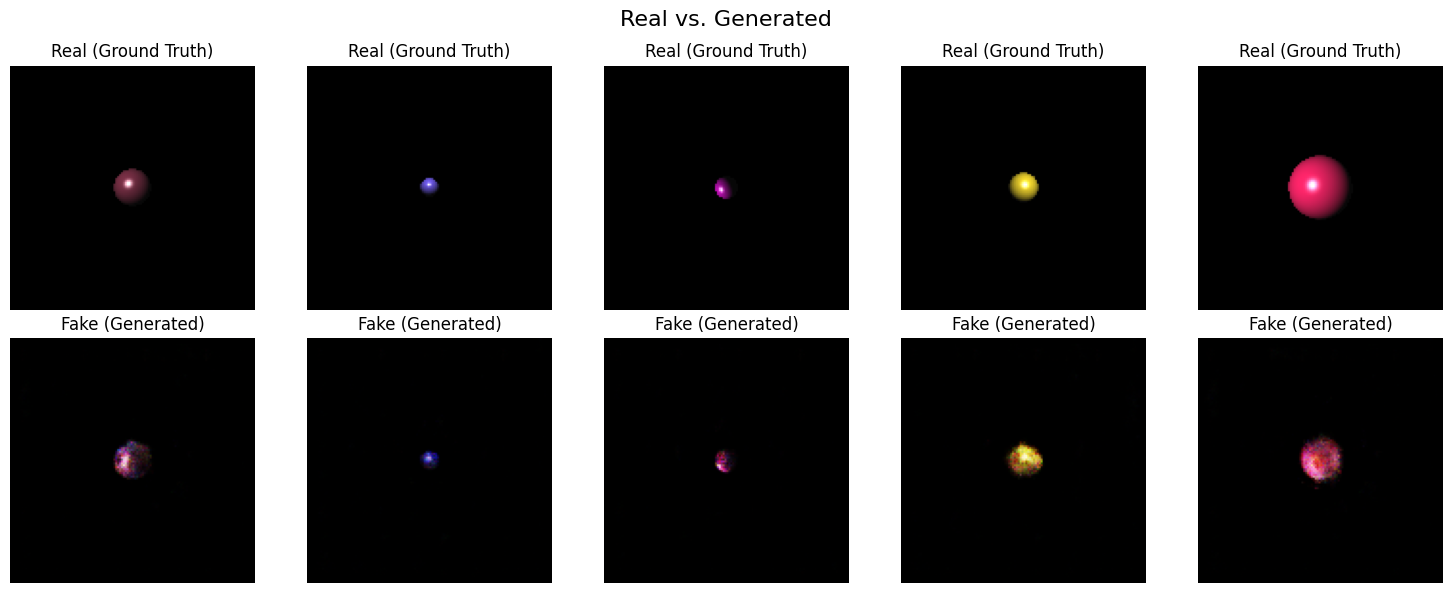

In [31]:
def compare_real_and_fake(generator, dataloader, device, num_examples=5):
    generator.eval()
    
    data_iter = iter(dataloader)
    cond, real_imgs = next(data_iter)
    
    cond = cond[:num_examples].to(device)
    real_imgs = real_imgs[:num_examples].to(device)
    
    with torch.no_grad():
        fake_imgs = generator(cond)
        
    real_imgs = (real_imgs * 0.5) + 0.5
    fake_imgs = (fake_imgs * 0.5) + 0.5
    
    real_imgs = real_imgs.cpu().permute(0, 2, 3, 1).numpy()
    
    
    fake_imgs = fake_imgs.cpu().permute(0, 2, 3, 1).numpy()
    
    fig, axes = plt.subplots(2, num_examples, figsize=(15, 6))
    fig.suptitle("Real vs. Generated", fontsize=16)
    
    for i in range(num_examples):
        axes[0, i].imshow(real_imgs[i])
        axes[0, i].axis('off')
        axes[0, i].set_title("Real (Ground Truth)")
        
        axes[1, i].imshow(fake_imgs[i])
        axes[1, i].axis('off')
        axes[1, i].set_title("Fake (Generated)")
        
    plt.tight_layout() 
    plt.show()


compare_real_and_fake(generator, test_loader, device, num_examples=5)

# Model 2nd version - Generator with noise input

In [32]:
class NoiseGenerator(nn.Module):
    def __init__(self, condition_dim=14, noise_dim=100, base_features=512, out_channels=3, num_upsample_blocks=5, latent_size=4):
        super().__init__()
        self.latent_size = latent_size
        self.base_features = base_features
        
        self.input_dim = condition_dim + noise_dim
        
        self.cond_to_feature_map = nn.Sequential(
            nn.Linear(self.input_dim, base_features * latent_size * latent_size),
            nn.ReLU(True)
        )
        
        layers = []
        in_features = base_features
        
        for _ in range(num_upsample_blocks - 1):
            out_features = in_features // 2 
            layers.extend([
                nn.ConvTranspose2d(in_features, out_features, kernel_size=4, stride=2, padding=1, bias=False),
                nn.BatchNorm2d(out_features),
                nn.ReLU(True)
            ])
            in_features = out_features
            
        layers.extend([
            nn.ConvTranspose2d(in_features, out_channels, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()
        ])

        self.upsample = nn.Sequential(*layers)

    def forward(self, noise, cond):
        x = torch.cat([noise, cond], dim=1)
        x = self.cond_to_feature_map(x)
        x = x.view(-1, self.base_features, self.latent_size, self.latent_size) 
        return self.upsample(x)

In [33]:
def warmup_generator(generator, train_loader, criterion_l1, loss_fn_vgg, optimizer, device, epochs=5, lambda_l1=100.0, lambda_lpips=10.0):
    print("Warm up generator")
    generator.train()
    for epoch in range(epochs):
        epoch_loss = 0
        for cond, real_imgs in train_loader:
            cond, real_imgs = cond.to(device), real_imgs.to(device)
            
            optimizer.zero_grad()
            noise = torch.randn(cond.size(0), 100, device=device)
            fake_imgs = generator(cond, noise)
            
            loss_G_l1 = criterion_l1(fake_imgs, real_imgs) * lambda_l1
            loss_G_lpips = loss_fn_vgg(fake_imgs, real_imgs).mean() * lambda_lpips
            loss_G = loss_G_l1 + loss_G_lpips
            loss_G.backward()
            optimizer.step()
            
            epoch_loss += loss_G.item()
            
        print(f"Warm up Epoch [{epoch+1}/{epochs}] | Loss: {epoch_loss/len(train_loader):.4f}")
    return generator


def validate(generator, discriminator, test_loader, criterion_gan, criterion_l1, loss_fn_vgg, device, lambda_l1=100.0, lambda_lpips=10.0):
    generator.eval()
    discriminator.eval()
    val_d_loss = 0
    val_g_loss = 0
    
    with torch.no_grad():
        for cond, real_imgs in test_loader:
            cond, real_imgs = cond.to(device), real_imgs.to(device)
            batch_size = real_imgs.size(0)   
            noise = torch.randn(batch_size, 100, device=device)
            fake_imgs = generator(cond, noise)
            pred_real = discriminator(real_imgs, cond)
            loss_D_real = criterion_gan(pred_real, torch.ones((batch_size, 1), device=device))  
            pred_fake = discriminator(fake_imgs, cond)
            loss_D_fake = criterion_gan(pred_fake, torch.zeros((batch_size, 1), device=device))
            loss_D = (loss_D_real + loss_D_fake) * 0.5
            val_d_loss += loss_D.item()
            pred_fake_for_G = discriminator(fake_imgs, cond)
            loss_G_gan = criterion_gan(pred_fake_for_G, torch.ones((batch_size, 1), device=device))
            loss_G_l1 = criterion_l1(fake_imgs, real_imgs) * lambda_l1
            loss_G_lpips = loss_fn_vgg(fake_imgs, real_imgs).mean() * lambda_lpips
            loss_G = loss_G_gan + loss_G_l1 + loss_G_lpips
            val_g_loss += loss_G.item()

    avg_d_loss = val_d_loss / len(test_loader)
    avg_g_loss = val_g_loss / len(test_loader)
    
    return avg_d_loss, avg_g_loss

def train_gan(generator, discriminator, train_loader, device, epochs=50, lambda_l1=100.0):
    print("Training GAN")
    lambda_lpips = 10.0
    
    criterion_gan = nn.BCELoss()
    criterion_l1 = nn.L1Loss()
    
    loss_fn_vgg = lpips.LPIPS(net='alex').to(device)
    for param in loss_fn_vgg.parameters():
        param.requires_grad = False
    
    generator_optimizer = optim.Adam(generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
    discriminator_optimizer = optim.Adam(discriminator.parameters(), lr=0.0001, betas=(0.5, 0.999))
    
    generator = warmup_generator(generator, train_loader, criterion_l1, loss_fn_vgg, generator_optimizer, device, epochs=7, 
                                 lambda_l1=lambda_l1, lambda_lpips=lambda_lpips)
    best_val_g = float('inf')
    
    for epoch in range(epochs):
        generator.train()
        discriminator.train()
        
        running_d_loss = 0.0
        running_g_loss = 0.0
        
        for cond, real_imgs in train_loader:
            cond, real_imgs = cond.to(device), real_imgs.to(device)
            batch_size = real_imgs.size(0)
            
            real_labels = torch.full((batch_size, 1), 0.9, device=device)
            fake_labels = torch.zeros((batch_size, 1), device=device)
            
            discriminator_optimizer.zero_grad()
            
            noise = torch.randn(cond.size(0), 100, device=device)
            fake_imgs = generator(cond, noise)
            
            pred_real = discriminator(real_imgs, cond)
            loss_D_real = criterion_gan(pred_real, real_labels)
            
            pred_fake = discriminator(fake_imgs.detach(), cond)
            loss_D_fake = criterion_gan(pred_fake, fake_labels)
            
            loss_D = (loss_D_real + loss_D_fake) * 0.5
            loss_D.backward()
            discriminator_optimizer.step()
            
            generator_optimizer.zero_grad()
            
            pred_fake_for_G = discriminator(fake_imgs, cond)
            
            loss_G_gan = criterion_gan(pred_fake_for_G, torch.ones((batch_size, 1), device=device))
            loss_G_l1 = criterion_l1(fake_imgs, real_imgs) * lambda_l1
            loss_G_lpips = loss_fn_vgg(fake_imgs, real_imgs).mean() * lambda_lpips
            
            loss_G = loss_G_gan + loss_G_l1 + loss_G_lpips
            loss_G.backward()
            generator_optimizer.step()
            
            running_d_loss += loss_D.item()
            running_g_loss += loss_G.item()
            
        val_avg_d, val_avg_g = validate(generator, discriminator, test_loader, criterion_gan, criterion_l1, loss_fn_vgg, device, lambda_l1, lambda_lpips=lambda_lpips)
                 
        print(f"Epoch [{epoch+1}/{epochs}]")
        print(f"Train Loss Discriminator: {running_d_loss/len(train_loader):.4f} | Train Loss Generator: {running_g_loss/len(train_loader):.4f}")
        print(f"Validation Loss Discriminator: {val_avg_d:.4f} | Validation Loss Generator: {val_avg_g:.4f}")
        
        if val_avg_g < best_val_g:
            best_val_g = val_avg_g
            print(f"New Best Generator found. Saving...")
            torch.save(generator.state_dict(), 'best_noise_generator.pth')
            torch.save(discriminator.state_dict(), 'best_noise_discriminator.pth')

second_generator = NoiseGenerator().to(device)
second_discriminator = Discriminator().to(device)

train_gan(second_generator, second_discriminator, train_loader, device, epochs=50, lambda_l1=100.0)

Training GAN
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Loading model from: c:\Users\Nel\OneDrive\Pulpit\mgr\sigk\lab3\venv\lib\site-packages\lpips\weights\v0.1\alex.pth
Warm up generator
Warm up Epoch [1/7] | Loss: 85.4525
Warm up Epoch [2/7] | Loss: 55.0439
Warm up Epoch [3/7] | Loss: 36.3343
Warm up Epoch [4/7] | Loss: 24.1909
Warm up Epoch [5/7] | Loss: 15.7912
Warm up Epoch [6/7] | Loss: 10.1778
Warm up Epoch [7/7] | Loss: 7.1927
Epoch [1/50]
Train Loss Discriminator: 0.5205 | Train Loss Generator: 7.8316
Validation Loss Discriminator: 0.2927 | Validation Loss Generator: 8.5648
New Best Generator found. Saving...
Epoch [2/50]
Train Loss Discriminator: 0.3266 | Train Loss Generator: 8.8724
Validation Loss Discriminator: 0.3018 | Validation Loss Generator: 8.6976
Epoch [3/50]
Train Loss Discriminator: 0.3187 | Train Loss Generator: 9.2300
Validation Loss Discriminator: 0.5792 | Validation Loss Generator: 8.7350
Epoch [4/50]
Train Loss Discriminator: 0.27

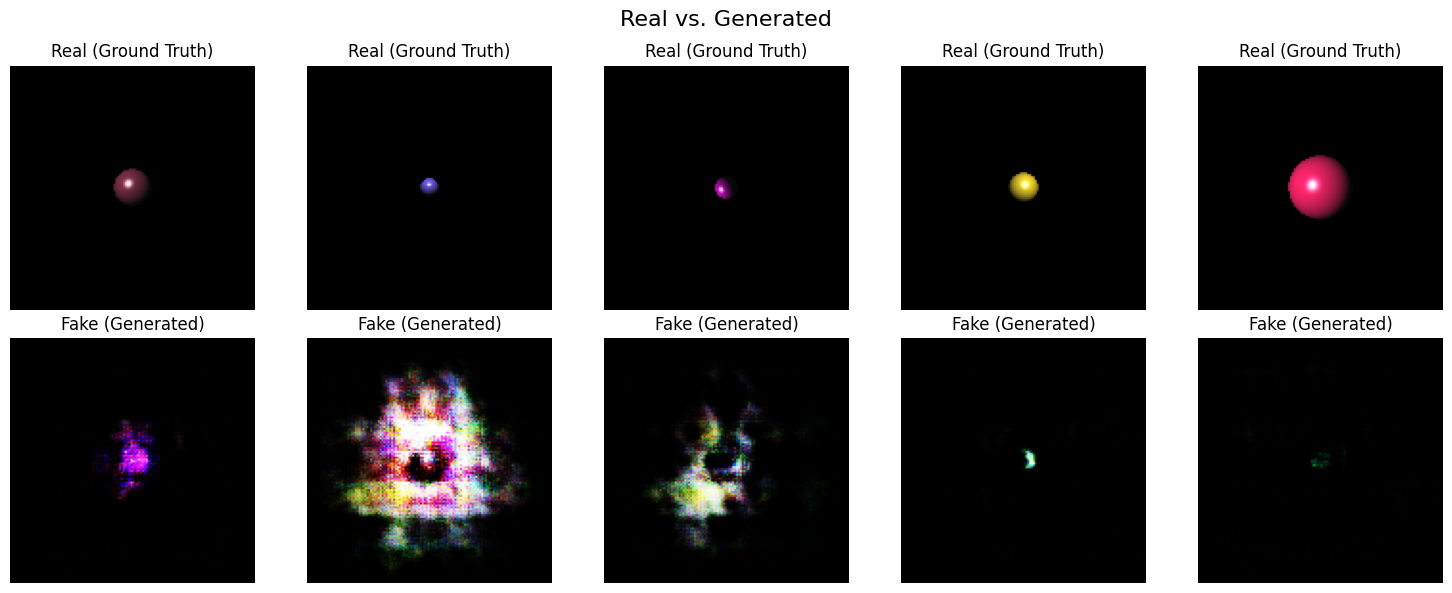

In [34]:
def compare_real_and_fake_noise(generator, dataloader, device, num_examples=5):
    generator.eval()
    
    data_iter = iter(dataloader)
    cond, real_imgs = next(data_iter)
    
    cond = cond[:num_examples].to(device)
    real_imgs = real_imgs[:num_examples].to(device)
    
    with torch.no_grad():
        noise = torch.randn(cond.size(0), 100, device=device)
        fake_imgs = generator(noise, cond)
        
    real_imgs = (real_imgs * 0.5) + 0.5
    fake_imgs = (fake_imgs * 0.5) + 0.5
    
    real_imgs = real_imgs.cpu().permute(0, 2, 3, 1).numpy()
    fake_imgs = fake_imgs.cpu().permute(0, 2, 3, 1).numpy()
    
    fig, axes = plt.subplots(2, num_examples, figsize=(15, 6))
    fig.suptitle("Real vs. Generated", fontsize=16)
    
    for i in range(num_examples):
        axes[0, i].imshow(real_imgs[i])
        axes[0, i].axis('off')
        axes[0, i].set_title("Real (Ground Truth)")
        
        axes[1, i].imshow(fake_imgs[i])
        axes[1, i].axis('off')
        axes[1, i].set_title("Fake (Generated)")
        
    plt.tight_layout()
    plt.show()


compare_real_and_fake_noise(second_generator, test_loader, device, num_examples=5)

# Metrics

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Loading model from: c:\Users\Nel\OneDrive\Pulpit\mgr\sigk\lab3\venv\lib\site-packages\lpips\weights\v0.1\alex.pth


Calculating metrics:   0%|          | 0/10 [00:00<?, ?it/s]

,Metoda,FLIP,LPIPS,SSIM,Hausdorff
0,neural renderer (without noise),0.0175,0.0534,0.9876,3.16
1,neural renderer (with noise),0.0227,0.0834,0.9646,6.25


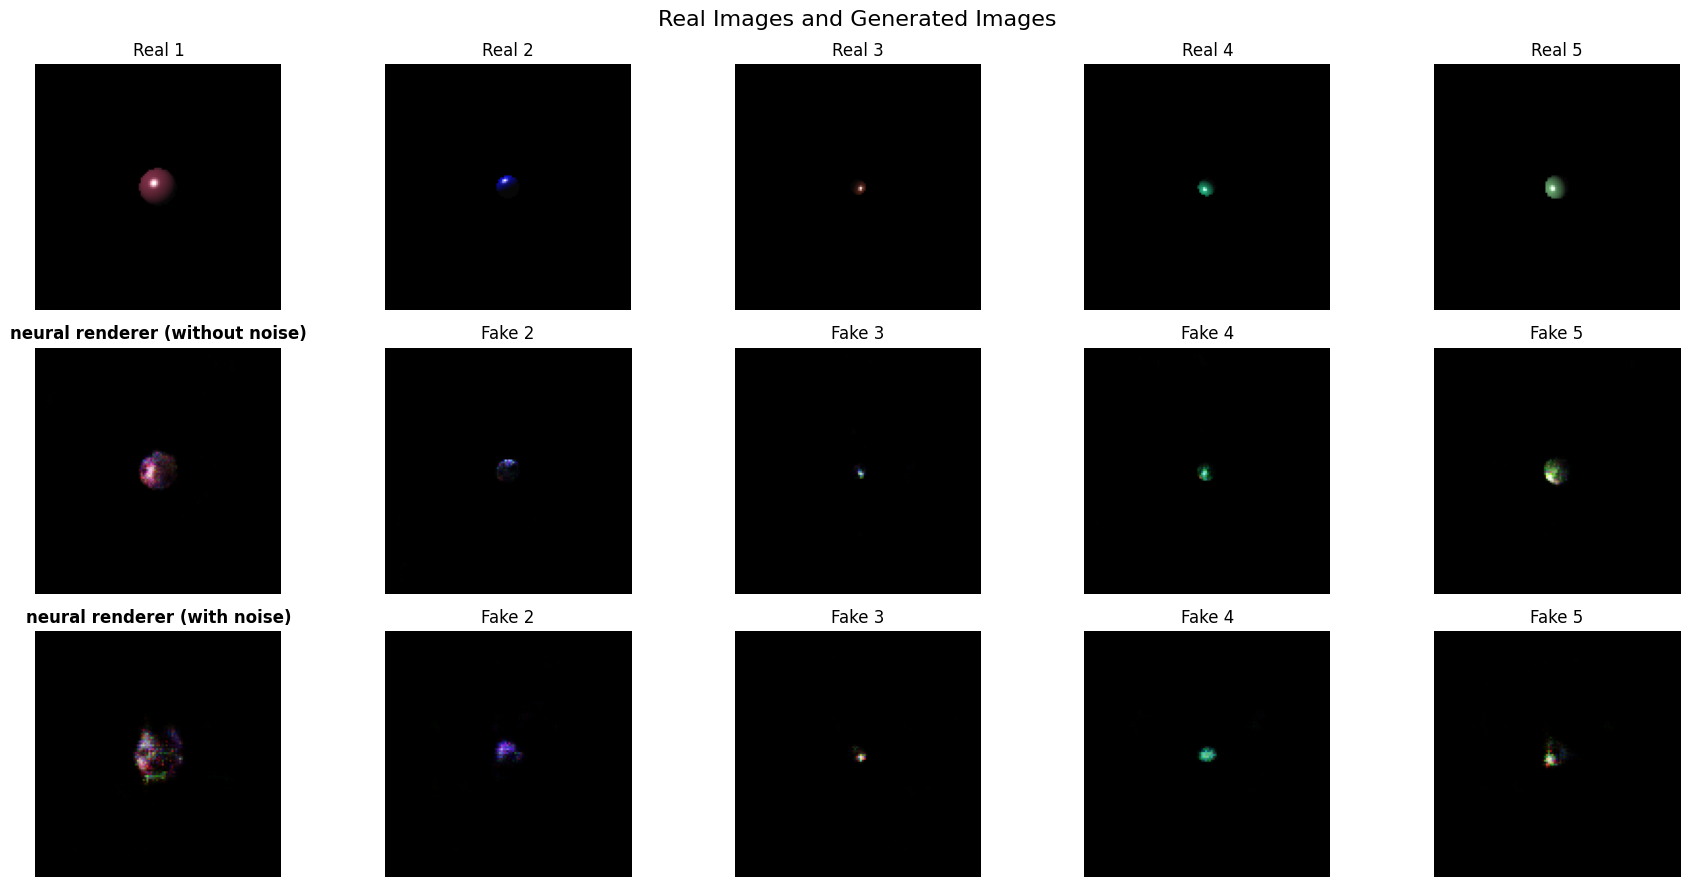

In [35]:
def calc_hausdorff(img_real, img_fake):
    gray_real = cv2.cvtColor(img_real, cv2.COLOR_RGB2GRAY)
    gray_fake = cv2.cvtColor(img_fake, cv2.COLOR_RGB2GRAY)
    
    edges_real = cv2.Canny(gray_real, 100, 200)
    edges_fake = cv2.Canny(gray_fake, 100, 200)
    
    pts_real = np.column_stack(np.where(edges_real > 0))
    pts_fake = np.column_stack(np.where(edges_fake > 0))
    
    if len(pts_real) == 0 or len(pts_fake) == 0: 
        return 0.0
        
    forward = directed_hausdorff(pts_real, pts_fake)[0]
    backward = directed_hausdorff(pts_fake, pts_real)[0]
    return max(forward, backward)

def evaluate_and_compare_models(models_info, test_loader, device):   
    loss_fn_vgg = lpips.LPIPS(net='alex').to(device)
    flip_loss_fn = LDRFLIPLoss().to(device) 
    
    for info in models_info:
        info['model'].eval()
        info['total_lpips'] = 0.0
        info['total_ssim'] = 0.0
        info['total_hausdorff'] = 0.0
        info['total_flip'] = 0.0
        info['vis_fakes'] = [] 
        
    vis_reals = []

    with torch.no_grad():
        for i, (cond, real_imgs) in enumerate(tqdm(test_loader, desc="Calculating metrics")):
            cond, real_imgs = cond.to(device), real_imgs.to(device)
            
            real_norm = (real_imgs + 1) / 2.0
            real_np = (real_norm[0].cpu().numpy().transpose(1, 2, 0) * 255).astype(np.uint8)
            
            if i < 5:
                vis_reals.append(real_np)
                
            noise = torch.randn(real_imgs.size(0), 100, device=device)
            
            for info in models_info:
                if info['with_noise']:
                    fake_imgs = info['model'](cond, noise) 
                else:
                    fake_imgs = info['model'](cond)
                
                fake_norm = (fake_imgs + 1) / 2.0
                
                info['total_lpips'] += loss_fn_vgg(fake_imgs, real_imgs).mean().item()
                info['total_flip'] += flip_loss_fn(fake_norm, real_norm).mean().item()
                
                fake_np = (fake_norm[0].cpu().numpy().transpose(1, 2, 0) * 255).astype(np.uint8)
                
                if i < 5:
                    info['vis_fakes'].append(fake_np)
                    
                info['total_ssim'] += calculate_ssim(real_np, fake_np, channel_axis=2, data_range=255)
                info['total_hausdorff'] += calc_hausdorff(real_np, fake_np)

    num_samples = len(test_loader)
    results_list = []
    
    for info in models_info:
        results_list.append({
            'Metoda': info['name'],
            'FLIP': f"{info['total_flip'] / num_samples:.4f}",
            'LPIPS': f"{info['total_lpips'] / num_samples:.4f}",
            'SSIM': f"{info['total_ssim'] / num_samples:.4f}",
            'Hausdorff': f"{info['total_hausdorff'] / num_samples:.2f}"
        })
        
    display(pd.DataFrame(results_list)) 
    
    num_models = len(models_info)
    fig, axes = plt.subplots(num_models + 1, 5, figsize=(18, 3 * (num_models + 1)))
    fig.suptitle("Real Images and Generated Images", fontsize=16)
    
    for idx in range(5):
        if idx < len(vis_reals):
            axes[0, idx].imshow(vis_reals[idx])
            axes[0, idx].axis('off')
            axes[0, idx].set_title(f"Real {idx+1}")
            
            for m_idx, info in enumerate(models_info):
                ax = axes[m_idx + 1, idx]
                ax.imshow(info['vis_fakes'][idx])
                ax.axis('off')
                
                if idx == 0:
                    ax.set_title(info['name'], fontweight='bold')
                else:
                    ax.set_title(f"Fake {idx+1}")
                    
    plt.tight_layout()
    plt.show()

best_generator = Generator().to(device)
best_noise_generator = NoiseGenerator().to(device)
best_generator.load_state_dict(torch.load('best_generator.pth', map_location=device))
best_noise_generator.load_state_dict(torch.load('best_noise_generator.pth', map_location=device))

models_to_test = [
    {
        "name": "neural renderer (without noise)", 
        "model": generator, 
        "with_noise": False
    },
    {
        "name": "neural renderer (with noise)", 
        "model": second_generator, 
        "with_noise": True
    }
]

evaluate_and_compare_models(models_to_test, test_loader, device)